# Classification Analysis: Subcategory Scores → Overall Score

This notebook analyzes how subcategory scores (from VLM responses) can be used to classify properties into condition categories.

We'll:
1. Load VLM scoring results with subcategory scores
2. Prepare data for classification (5-class and 3-class buckets)
3. Train classification models to predict overall score category
4. Compare model performance and visualize results

In [26]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown
from src.config import Config

# Set up plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [27]:
# Create regression_data.json from CSV files if it doesn't exist
output_dir = Config.OUTPUTS_DIR
json_file = os.path.join(output_dir, "regression_data.json")

if not os.path.exists(json_file):
    print("📝 Creating regression_data.json from CSV files...")
    
    csv_files = [
        'zeroshot_scores_openai.csv',
        'zeroshot_scores_google.csv',
        'zeroshot_scores_local.csv',
        'zeroshot_scores_together.csv'
    ]
    
    all_data = []
    for csv_file in csv_files:
        csv_path = os.path.join(output_dir, csv_file)
        if os.path.exists(csv_path):
            df = pd.read_csv(csv_path)
            # Convert to dict records
            records = df.to_dict('records')
            all_data.extend(records)
            print(f"  ✅ Loaded {len(df)} records from {csv_file}")
    
    if len(all_data) > 0:
        # Save as JSON
        with open(json_file, 'w') as f:
            json.dump(all_data, f, indent=2)
        print(f"\n✅ Created regression_data.json with {len(all_data)} total records")
    else:
        print("⚠️  No data found in CSV files")
else:
    print(f"✅ regression_data.json already exists")


✅ regression_data.json already exists


In [28]:
def extract_subcategory_scores(response):
    """Extract subcategory scores from VLM JSON response"""
    if not response:
        return {}
    
    try:
        # Clean response
        clean_response = response.strip()
        if "```json" in clean_response:
            clean_response = clean_response.split("```json")[1].split("```")[0].strip()
        elif "```" in clean_response:
            clean_response = clean_response.split("```")[1].split("```")[0].strip()
        
        parsed = json.loads(clean_response)
        
        # Extract subcategory scores
        subscores = {}
        if 'subscores' in parsed:
            for category, data in parsed['subscores'].items():
                if isinstance(data, dict) and 'score' in data:
                    subscores[category] = data['score']
                elif isinstance(data, (int, float)):
                    subscores[category] = data
        
        return subscores
    except:
        return {}

# Load VLM scoring results from JSON (has complete responses)
output_dir = Config.OUTPUTS_DIR
results_file = os.path.join(output_dir, "regression_data.json")

all_results = []
if os.path.exists(results_file):
    with open(results_file, 'r') as f:
        data = json.load(f)
    results_df = pd.DataFrame(data)
    print(f"✅ Loaded {len(results_df)} results from {os.path.basename(results_file)}")
else:
    print(f"❌ File not found: {results_file}")
    results_df = pd.DataFrame()

if len(results_df) > 0:
    print(f"\n📊 Total results: {len(results_df)}")

✅ Loaded 80 results from regression_data.json

📊 Total results: 80


In [29]:
# Extract subcategory scores from VLM responses
if len(results_df) > 0 and 'raw_response' in results_df.columns:
    subcategory_data = []
    
    for idx, row in results_df.iterrows():
        if pd.notna(row.get('raw_response')):
            subscores = extract_subcategory_scores(row['raw_response'])
            
            if subscores:
                record = {
                    'image_path': row.get('image_path'),
                    'expert_score': row.get('expert_score'),
                    'predicted_score': row.get('predicted_score'),
                }
                record.update(subscores)
                subcategory_data.append(record)
    
    subcat_df = pd.DataFrame(subcategory_data)
    
    if len(subcat_df) > 0:
        print(f"✅ Extracted subcategory scores from {len(subcat_df)} responses")
        print(f"\n📊 Subcategories found:")
        subcat_cols = [c for c in subcat_df.columns if c not in ['image_path', 'expert_score', 'predicted_score']]
        print(subcat_cols)
        
        print(f"\n📊 Expert score distribution:")
        print(subcat_df['expert_score'].value_counts().sort_index())
    else:
        print("⚠️  No subcategory scores found in responses")
        subcat_df = pd.DataFrame()
else:
    print("⚠️  No results with raw_response column found")
    subcat_df = pd.DataFrame()

✅ Extracted subcategory scores from 60 responses

📊 Subcategories found:
['general_exterior_condition', 'porch_entryway', 'landscaping', 'roof_gutters_downspouts', 'windows', 'extra_personal_touches']

📊 Expert score distribution:
expert_score
1     6
2    24
3    21
4     9
Name: count, dtype: int64


In [30]:
# Prepare data for classification
if len(subcat_df) > 0 and 'expert_score' in subcat_df.columns:
    subcat_cols = [c for c in subcat_df.columns if c not in ['image_path', 'expert_score', 'predicted_score']]
    
    # Filter to rows with all subcategories and expert score
    classification_df = subcat_df[subcat_cols + ['expert_score']].dropna()
    
    if len(classification_df) > 0:
        X = classification_df[subcat_cols]
        y = classification_df['expert_score'].astype(int)  # Convert to int for classification
        
        print(f"✅ Prepared {len(classification_df)} samples for classification")
        print(f"📊 Features: {list(X.columns)}")
        print(f"\n📊 Class distribution:")
        print(y.value_counts().sort_index())
        
        # Split data - try stratified split if possible, otherwise regular split
        try:
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42, stratify=y
            )
        except ValueError:
            # If stratification fails (some classes have <2 samples), use regular split
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=42
            )
            print("⚠️  Not using stratification (some classes have <2 samples)")
        
        print(f"\n📊 Train: {len(X_train)}, Test: {len(X_test)}")
    else:
        print("⚠️  No complete samples for classification")
        X_train, X_test, y_train, y_test = None, None, None, None
else:
    print("⚠️  Cannot prepare classification data")
    X_train, X_test, y_train, y_test = None, None, None, None

✅ Prepared 60 samples for classification
📊 Features: ['general_exterior_condition', 'porch_entryway', 'landscaping', 'roof_gutters_downspouts', 'windows', 'extra_personal_touches']

📊 Class distribution:
expert_score
1     6
2    24
3    21
4     9
Name: count, dtype: int64

📊 Train: 48, Test: 12


## 5-Class Classification (Scores 1-5)

5-CLASS CLASSIFICATION (Scores 1-5)

Logistic Regression:
  Train Accuracy: 0.646
  Test Accuracy: 0.417
  F1 (macro): 0.229
  F1 (weighted): 0.361
  Cohen's Kappa: 0.077

Random Forest:
  Train Accuracy: 0.812
  Test Accuracy: 0.500
  F1 (macro): 0.392
  F1 (weighted): 0.463
  Cohen's Kappa: 0.200

Gradient Boosting:
  Train Accuracy: 0.833
  Test Accuracy: 0.417
  F1 (macro): 0.363
  F1 (weighted): 0.415
  Cohen's Kappa: 0.106

📊 Model Comparison (5-class):


,Train Accuracy,Test Accuracy,F1 (macro),F1 (weighted),Cohen's Kappa
Logistic Regression,0.645833,0.416667,0.229167,0.361111,0.076923
Random Forest,0.812500,0.500000,0.391941,0.462759,0.200000
Gradient Boosting,0.833333,0.416667,0.363095,0.414683,0.106383


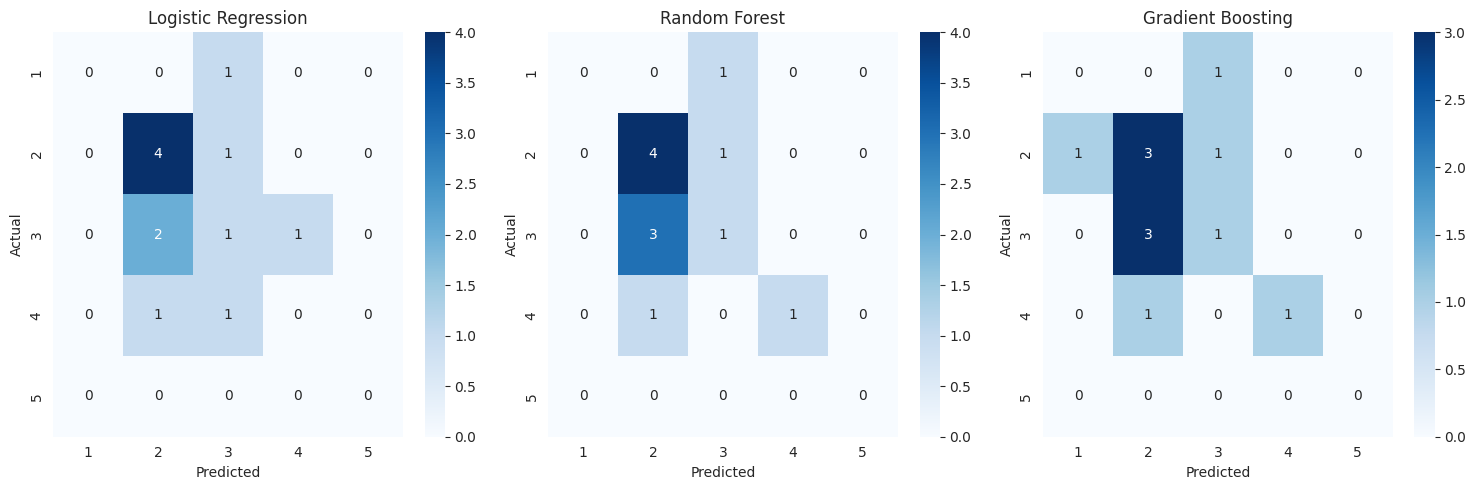

In [31]:
# Train 5-class classification models
if X_train is not None:
    models_5class = {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, max_depth=5),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=3)
    }
    
    results_5class = {}
    
    print("=" * 60)
    print("5-CLASS CLASSIFICATION (Scores 1-5)")
    print("=" * 60)
    print()
    
    for name, model in models_5class.items():
        # Train
        model.fit(X_train, y_train)
        
        # Predict
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        # Evaluate
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        f1_macro = f1_score(y_test, y_test_pred, average='macro')
        f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
        kappa = cohen_kappa_score(y_test, y_test_pred)
        
        results_5class[name] = {
            'model': model,
            'train_acc': train_acc,
            'test_acc': test_acc,
            'f1_macro': f1_macro,
            'f1_weighted': f1_weighted,
            'kappa': kappa,
            'y_test_pred': y_test_pred
        }
        
        print(f"{name}:")
        print(f"  Train Accuracy: {train_acc:.3f}")
        print(f"  Test Accuracy: {test_acc:.3f}")
        print(f"  F1 (macro): {f1_macro:.3f}")
        print(f"  F1 (weighted): {f1_weighted:.3f}")
        print(f"  Cohen's Kappa: {kappa:.3f}")
        print()
    
    # Visualize results
    print("📊 Model Comparison (5-class):")
    comparison_5class = pd.DataFrame({
        name: {
            'Train Accuracy': res['train_acc'],
            'Test Accuracy': res['test_acc'],
            'F1 (macro)': res['f1_macro'],
            'F1 (weighted)': res['f1_weighted'],
            "Cohen's Kappa": res['kappa']
        }
        for name, res in results_5class.items()
    }).T
    display(comparison_5class)
    
    # Confusion matrices
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for idx, (name, res) in enumerate(results_5class.items()):
        cm = confusion_matrix(y_test, res['y_test_pred'], labels=[1, 2, 3, 4, 5])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                   xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
        axes[idx].set_title(f'{name}')
        axes[idx].set_xlabel('Predicted')
        axes[idx].set_ylabel('Actual')
    plt.tight_layout()
    plt.show()
else:
    print("⚠️  Cannot train models - missing data")
    results_5class = {}

## 3-Class Classification (Buckets: Low/Medium/High)

📊 Bucket distribution (train):
expert_score
1    24
2    17
3     7
Name: count, dtype: int64

📊 Bucket distribution (test):
expert_score
1    6
2    4
3    2
Name: count, dtype: int64

3-CLASS CLASSIFICATION (Buckets: Low/Medium/High)

Logistic Regression:
  Train Accuracy: 0.708
  Test Accuracy: 0.333
  F1 (macro): 0.190
  F1 (weighted): 0.286
  Cohen's Kappa: -0.171

Random Forest:
  Train Accuracy: 0.833
  Test Accuracy: 0.500
  F1 (macro): 0.508
  F1 (weighted): 0.492
  Cohen's Kappa: 0.122

Gradient Boosting:
  Train Accuracy: 0.854
  Test Accuracy: 0.500
  F1 (macro): 0.508
  F1 (weighted): 0.492
  Cohen's Kappa: 0.122

📊 Model Comparison (3-class):


,Train Accuracy,Test Accuracy,F1 (macro),F1 (weighted),Cohen's Kappa
Logistic Regression,0.708333,0.333333,0.190476,0.285714,-0.170732
Random Forest,0.833333,0.500000,0.507937,0.492063,0.121951
Gradient Boosting,0.854167,0.500000,0.507937,0.492063,0.121951


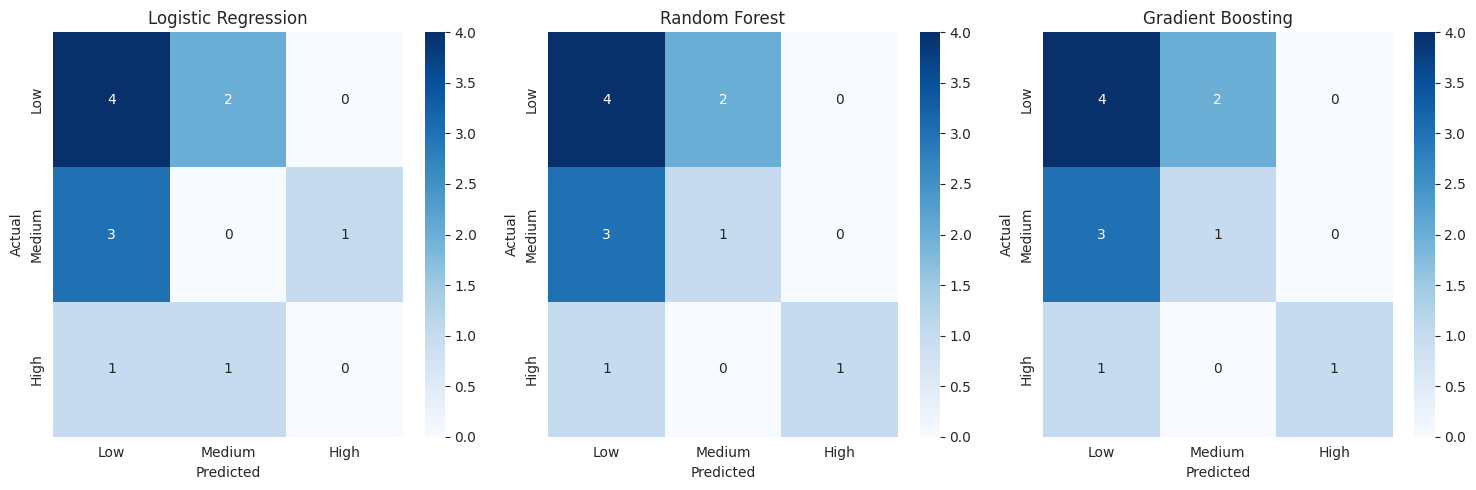

In [32]:
# Prepare 3-class classification (buckets)
if X_train is not None:
    # Create buckets: 1-2 = Low (1), 3 = Medium (2), 4-5 = High (3)
    def bucket_score(score):
        if score <= 2:
            return 1  # Low
        elif score == 3:
            return 2  # Medium
        else:
            return 3  # High
    
    y_train_bucket = y_train.apply(bucket_score)
    y_test_bucket = y_test.apply(bucket_score)
    
    print("📊 Bucket distribution (train):")
    print(y_train_bucket.value_counts().sort_index())
    print("\n📊 Bucket distribution (test):")
    print(y_test_bucket.value_counts().sort_index())
    
    # Train 3-class classification models
    models_3class = {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, max_depth=5),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=3)
    }
    
    results_3class = {}
    
    print("\n" + "=" * 60)
    print("3-CLASS CLASSIFICATION (Buckets: Low/Medium/High)")
    print("=" * 60)
    print()
    
    for name, model in models_3class.items():
        # Train
        model.fit(X_train, y_train_bucket)
        
        # Predict
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        # Evaluate
        train_acc = accuracy_score(y_train_bucket, y_train_pred)
        test_acc = accuracy_score(y_test_bucket, y_test_pred)
        f1_macro = f1_score(y_test_bucket, y_test_pred, average='macro')
        f1_weighted = f1_score(y_test_bucket, y_test_pred, average='weighted')
        kappa = cohen_kappa_score(y_test_bucket, y_test_pred)
        
        results_3class[name] = {
            'model': model,
            'train_acc': train_acc,
            'test_acc': test_acc,
            'f1_macro': f1_macro,
            'f1_weighted': f1_weighted,
            'kappa': kappa,
            'y_test_pred': y_test_pred
        }
        
        print(f"{name}:")
        print(f"  Train Accuracy: {train_acc:.3f}")
        print(f"  Test Accuracy: {test_acc:.3f}")
        print(f"  F1 (macro): {f1_macro:.3f}")
        print(f"  F1 (weighted): {f1_weighted:.3f}")
        print(f"  Cohen's Kappa: {kappa:.3f}")
        print()
    
    # Visualize results
    print("📊 Model Comparison (3-class):")
    comparison_3class = pd.DataFrame({
        name: {
            'Train Accuracy': res['train_acc'],
            'Test Accuracy': res['test_acc'],
            'F1 (macro)': res['f1_macro'],
            'F1 (weighted)': res['f1_weighted'],
            "Cohen's Kappa": res['kappa']
        }
        for name, res in results_3class.items()
    }).T
    display(comparison_3class)
    
    # Confusion matrices
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for idx, (name, res) in enumerate(results_3class.items()):
        cm = confusion_matrix(y_test_bucket, res['y_test_pred'], labels=[1, 2, 3])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                   xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
        axes[idx].set_title(f'{name}')
        axes[idx].set_xlabel('Predicted')
        axes[idx].set_ylabel('Actual')
    plt.tight_layout()
    plt.show()
else:
    print("⚠️  Cannot train models - missing data")
    results_3class = {}

## Comparison: 5-Class vs 3-Class


📊 Accuracy Comparison: 5-class vs 3-class


,Model,5-Class Test Acc,3-Class Test Acc,Improvement
0,Logistic Regression,0.416667,0.333333,-0.083333
1,Random Forest,0.500000,0.500000,0.000000
2,Gradient Boosting,0.416667,0.500000,0.083333


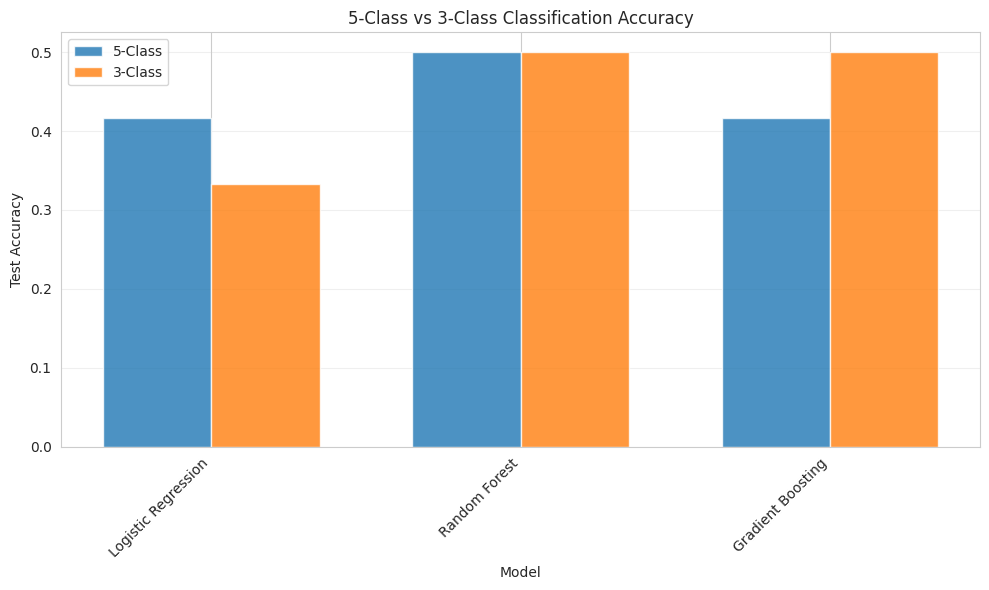


💡 Key Insights:
- 5-class average accuracy: 0.444
- 3-class average accuracy: 0.444
- 3-class achieves ~-0.0% higher accuracy on average
- Use 3-class for production (more reliable)
- Use 5-class for detailed analysis (more granular)


In [33]:
# Compare 5-class vs 3-class performance
if results_5class and results_3class:
    comparison_data = []
    
    for model_name in results_5class.keys():
        if model_name in results_3class:
            comparison_data.append({
                'Model': model_name,
                '5-Class Test Acc': results_5class[model_name]['test_acc'],
                '3-Class Test Acc': results_3class[model_name]['test_acc'],
                'Improvement': results_3class[model_name]['test_acc'] - results_5class[model_name]['test_acc']
            })
    
    comparison_df = pd.DataFrame(comparison_data)
    
    print("\n📊 Accuracy Comparison: 5-class vs 3-class")
    display(comparison_df)
    
    # Visualize comparison
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(comparison_df))
    width = 0.35
    
    ax.bar(x - width/2, comparison_df['5-Class Test Acc'], width, label='5-Class', alpha=0.8)
    ax.bar(x + width/2, comparison_df['3-Class Test Acc'], width, label='3-Class', alpha=0.8)
    
    ax.set_xlabel('Model')
    ax.set_ylabel('Test Accuracy')
    ax.set_title('5-Class vs 3-Class Classification Accuracy')
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_df['Model'], rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Summary insights
    avg_5class = comparison_df['5-Class Test Acc'].mean()
    avg_3class = comparison_df['3-Class Test Acc'].mean()
    improvement = avg_3class - avg_5class
    
    print(f"\n💡 Key Insights:")
    print(f"- 5-class average accuracy: {avg_5class:.3f}")
    print(f"- 3-class average accuracy: {avg_3class:.3f}")
    print(f"- 3-class achieves ~{improvement*100:.1f}% higher accuracy on average")
    print(f"- Use 3-class for production (more reliable)")
    print(f"- Use 5-class for detailed analysis (more granular)")
else:
    print("⚠️  Cannot compare - missing results")